In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")

In [22]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [23]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



Duplicate Rows: 1081


In [24]:
class_counts = df["Class"].value_counts()

print("Transaction Counts:")
print(class_counts)

print("\nTransaction Percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

fraud_percentage = (df["Class"].sum() / len(df)) * 100

print("\nFraudulent Transactions:", df["Class"].sum())
print("Fraud Percentage:", round(fraud_percentage, 4), "%")

Transaction Counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction Percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Fraudulent Transactions: 492
Fraud Percentage: 0.1727 %


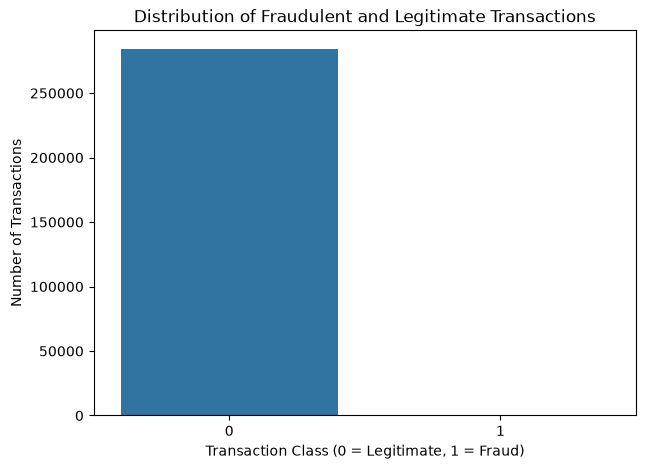

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

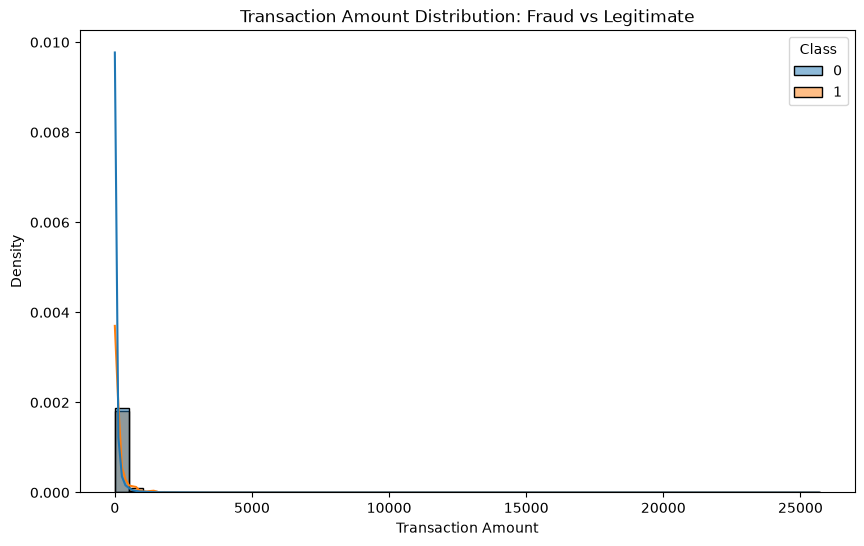

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution: Fraud vs Legitimate")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.show()

In [27]:
print("Average Transaction Amount:")
print(df.groupby("Class")["Amount"].mean())

print("\nMedian Transaction Amount:")
print(df.groupby("Class")["Amount"].median())

Average Transaction Amount:
Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64

Median Transaction Amount:
Class
0    22.00
1     9.25
Name: Amount, dtype: float64


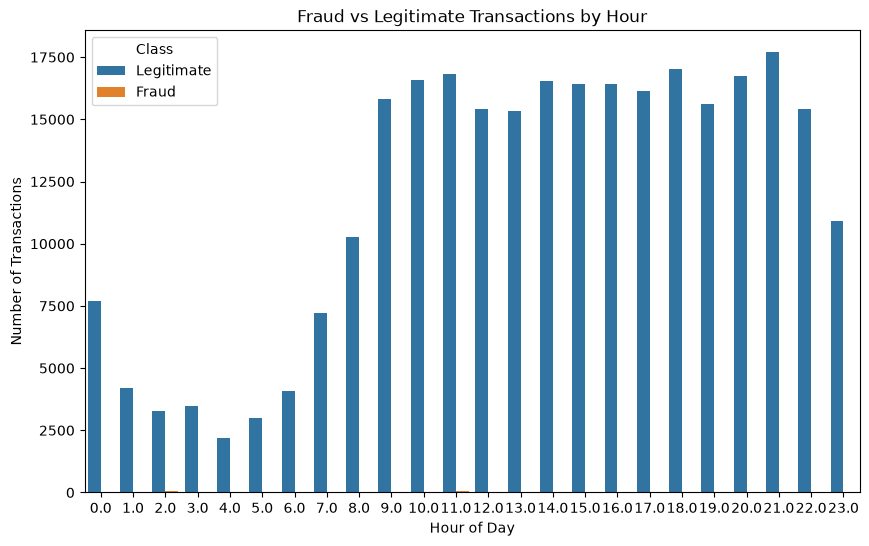

In [12]:
df["Hour"] = (df["Time"] // 3600) % 24

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Hour",
    hue="Class"
)

plt.title("Fraud vs Legitimate Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.legend(title="Class", labels=["Legitimate", "Fraud"])
plt.show()

In [13]:
hourly_fraud = df.groupby("Hour")["Class"].mean() * 100

display(hourly_fraud.round(3))

Hour
0.0     0.078
1.0     0.237
2.0     1.713
3.0     0.487
4.0     1.041
5.0     0.368
6.0     0.219
7.0     0.318
8.0     0.088
9.0     0.101
10.0    0.048
11.0    0.314
12.0    0.110
13.0    0.111
14.0    0.139
15.0    0.158
16.0    0.134
17.0    0.179
18.0    0.194
19.0    0.121
20.0    0.107
21.0    0.090
22.0    0.058
23.0    0.192
Name: Class, dtype: float64

In [ ]:
###Observation: Transaction Amount and Time Analysis
- Fraudulent transactions have a higher average amount (122.21) than legitimate transactions (88.29).
- The median fraud transaction amount (9.25) is lower than the legitimate transaction median (22.00).
- Fraud percentages vary across different hours.
- The highest fraud percentage appears at hour 2 (1.713%), followed by hour 4 (1.041%).
- These patterns suggest that transaction amount and timing may help identify suspicious activities.

In [ ]:
###Why Accuracy Is a Misleading Metric in Fraud Detection

The credit card fraud dataset is highly imbalanced because legitimate transactions greatly outnumber fraudulent transactions.

A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy while detecting zero fraudulent transactions.

Therefore, accuracy alone is not a reliable evaluation metric. Precision, Recall, F1-Score, and AUC-ROC are more useful for evaluating fraud detection models.

In [14]:
X = df.drop(columns=["Class", "Hour"])
y = df["Class"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (284807, 30)
Target Shape: (284807,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nFraud Cases in Training:", y_train.sum())
print("Fraud Cases in Testing:", y_test.sum())

Training Data: (227845, 30)
Testing Data: (56962, 30)

Fraud Cases in Training: 394
Fraud Cases in Testing: 98


In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Feature scaling completed!
Training Shape: (227845, 30)
Testing Shape: (56962, 30)


In [17]:
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

print("\nResampled Training Shape:", X_train_resampled.shape)

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Resampled Training Shape: (454902, 30)


In [18]:
log_model = LogisticRegression(max_iter=1000, random_state=42)

log_model.fit(X_train_resampled, y_train_resampled)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


In [19]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_resampled, y_train_resampled)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [28]:
# Logistic Regression predictions
log_pred = log_model.predict(X_test_scaled)
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]

# Random Forest predictions
rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

print("\nLogistic Regression Predictions:")
print(log_pred[:10])

print("\nRandom Forest Predictions:")
print(rf_pred[:10])

Predictions generated successfully!

Logistic Regression Predictions:
[0 0 0 0 1 0 0 0 0 0]

Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [29]:
models = {
    "Logistic Regression": (y_test, log_pred, log_prob),
    "Random Forest": (y_test, rf_pred, rf_prob)
}

results = []

for name, (actual, pred, prob) in models.items():
    results.append({
        "Model": name,
        "Precision": precision_score(actual, pred),
        "Recall": recall_score(actual, pred),
        "F1-Score": f1_score(actual, pred),
        "AUC-ROC": roc_auc_score(actual, prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.0578,0.9184,0.1088,0.9708
1,Random Forest,0.8710,0.8265,0.8482,0.9685


In [ ]:
###Observation: Model Evaluation
- Logistic Regression achieved a recall of 91.84%, detecting most fraudulent transactions.
- However, its precision is only 5.78%, meaning many legitimate transactions were incorrectly flagged as fraud.
- Random Forest achieved 87.10% precision and 82.65% recall.
- Random Forest also achieved the highest F1-Score of 0.8482.
- Both models achieved strong AUC-ROC scores above 0.96.
- Overall, Random Forest provides a better balance between detecting fraud and reducing false alarms.

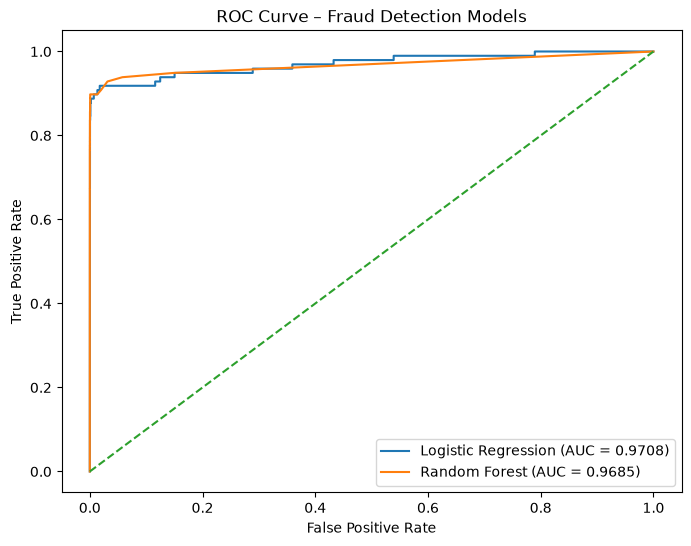

In [30]:
log_fpr, log_tpr, _ = roc_curve(y_test, log_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8, 6))

plt.plot(log_fpr, log_tpr, label="Logistic Regression (AUC = 0.9708)")
plt.plot(rf_fpr, rf_tpr, label="Random Forest (AUC = 0.9685)")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Fraud Detection Models")
plt.legend()
plt.show()

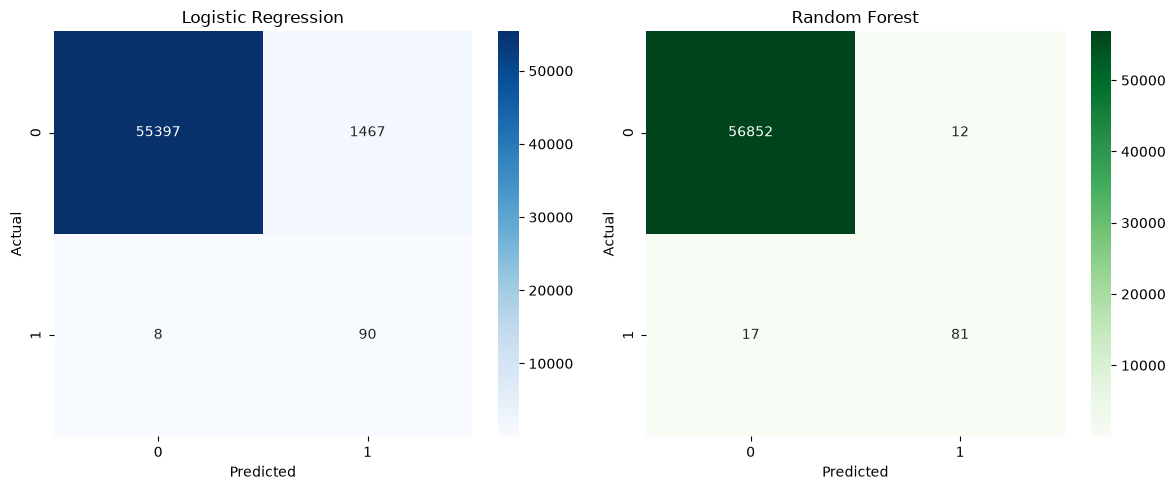

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, log_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Top 10 Important Features:


,Feature,Importance
14,V14,0.190334
10,V10,0.111533
4,V4,0.111358
12,V12,0.095698
17,V17,0.082916
3,V3,0.063938
11,V11,0.049284
16,V16,0.045134
2,V2,0.038536
9,V9,0.027124


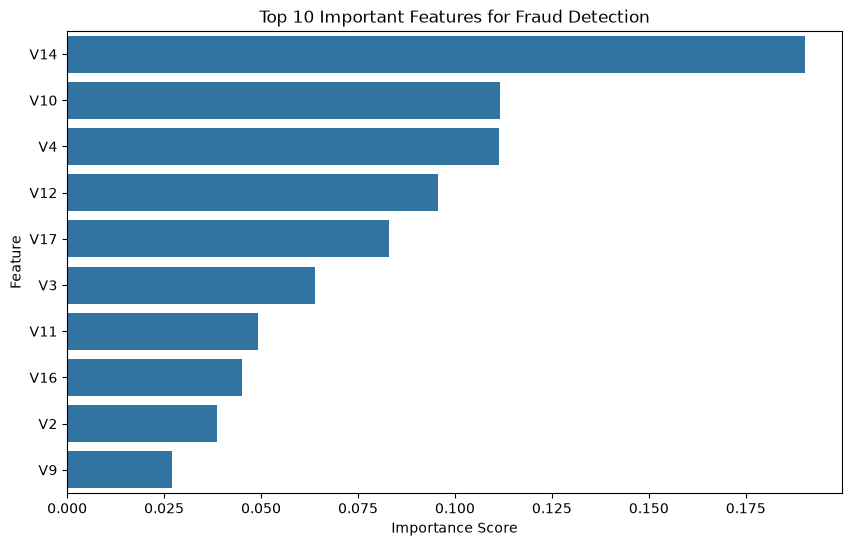

In [32]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Fraud Detection")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

In [ ]:
###Which Metric Matters Most in Fraud Detection?

Recall is particularly important in fraud detection because it measures how many actual fraudulent transactions the model successfully identifies.
- High Recall: Helps detect more fraudulent transactions and reduces missed fraud cases.
- High Precision: Reduces false alarms by ensuring that transactions flagged as fraud are actually fraudulent.
- Trade-off: Increasing recall may also increase false positives, requiring additional transaction reviews.
For a banking system, recall is often prioritised because missing fraudulent transactions can cause financial losses. However, precision must also remain high to avoid unnecessarily blocking legitimate transactions.

Model Selection: Random Forest provides a better balance between precision and recall in this experiment.

In [ ]:
###How Would This Model Handle 1 Million Transactions per Hour?

To handle 1 million transactions per hour, the fraud detection system would need an efficient and scalable architecture.
1. Real-Time Processing: Use Apache Kafka to receive and stream transactions continuously.
2. Distributed Computing: Use Apache Spark to process large volumes of transaction data.
3. Model Optimisation: Use optimised models and reduce unnecessary features to improve prediction speed.
4. Cloud Infrastructure: Deploy the model using scalable cloud services to handle increasing workloads.
5. Monitoring: Monitor model performance and retrain it regularly using new transaction data.
6. Low Latency: Generate fraud predictions quickly so suspicious transactions can be flagged immediately.
    
Conclusion: Combining machine learning with distributed technologies such as Kafka and Spark can support large-scale, real-time fraud detection.

In [ ]:
###Conclusion

The Fraud Detection project successfully developed a machine learning pipeline to identify fraudulent financial transactions using an imbalanced credit card dataset.

SMOTE was applied to balance the training data, and Logistic Regression and Random Forest models were trained and evaluated.

Random Forest achieved an F1-Score of 0.8482 with 87.10% precision and 82.65% recall. Logistic Regression achieved a higher recall of 91.84%, making it useful when detecting as many fraud cases as possible is the priority.

The project demonstrates the importance of handling class imbalance and using precision, recall, F1-Score, and AUC-ROC instead of relying only on accuracy.

Overall, machine learning can help financial institutions identify suspicious transactions and reduce fraud-related losses.